# 1. Import Libraries

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical


# 2. Load and Preprocess CIFAR-10 Dataset

In [2]:

# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()


In [3]:

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


In [4]:

# One-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


In [5]:

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)


Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)


# 3. Display Sample Images

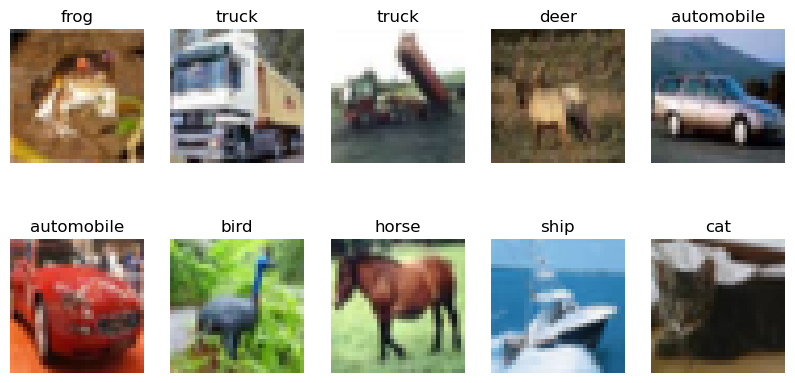

In [6]:

class_names = [
    'airplane','automobile','bird','cat','deer',
    'dog','frog','horse','ship','truck'
]

plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.show()


# 4. Basic CNN Model

In [7]:

def basic_cnn():

    model = models.Sequential([

        layers.Conv2D(32,(3,3),
                      activation='relu',
                      input_shape=(32,32,3)),

        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64,(3,3),
                      activation='relu'),

        layers.MaxPooling2D((2,2)),

        layers.Flatten(),

        layers.Dense(128,
                     activation='relu'),

        layers.Dense(10,
                     activation='softmax')
    ])

    return model

model = basic_cnn()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

history = model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.2)

test_loss, test_acc = model.evaluate(
    x_test,
    y_test_cat)

print("Test Accuracy:", test_acc)


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4426 - loss: 1.5466 - val_accuracy: 0.5300 - val_loss: 1.3166
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.5848 - loss: 1.1864 - val_accuracy: 0.5771 - val_loss: 1.1997
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6370 - loss: 1.0411 - val_accuracy: 0.6390 - val_loss: 1.0444
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6712 - loss: 0.9431 - val_accuracy: 0.6555 - val_loss: 0.9951
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6952 - loss: 0.8693 - val_accuracy: 0.6697 - val_loss: 0.9626
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7224 - loss: 0.8006 - val_accuracy: 0.6543 - val_loss: 1.0239
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7379 - loss: 0.7514 - val_accuracy: 0.6922 - val_loss: 0.9021
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7610 - loss: 0.6903 - val_accu

# 5. Experiment: Kernel Size Comparison

In [8]:

def cnn_kernel(kernel_size):

    model = models.Sequential([

        layers.Conv2D(
            32,
            kernel_size,
            activation='relu',
            input_shape=(32,32,3)),

        layers.MaxPooling2D(),

        layers.Conv2D(
            64,
            kernel_size,
            activation='relu'),

        layers.MaxPooling2D(),

        layers.Flatten(),

        layers.Dense(128,
                     activation='relu'),

        layers.Dense(10,
                     activation='softmax')
    ])

    return model

for k in [(3,3),(5,5)]:

    model = cnn_kernel(k)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    print(f"\nKernel Size: {k}")

    model.fit(
        x_train,
        y_train_cat,
        epochs=5,
        batch_size=64,
        verbose=1)

    loss, acc = model.evaluate(x_test,y_test_cat)

    print("Accuracy:",acc)



Kernel Size: (3, 3)
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.4725 - loss: 1.4703
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6124 - loss: 1.1132
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6614 - loss: 0.9721
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6953 - loss: 0.8776
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7226 - loss: 0.8007
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6987 - loss: 0.8826
Accuracy: 0.6987000107765198

Kernel Size: (5, 5)
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4470 - loss: 1.5395
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.5839 - loss: 1.1787
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6363 - loss: 1.0326
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.6731 - loss: 0.9364
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.6994 - lo

# 6. Experiment: Stride Comparison

In [9]:

def cnn_stride(stride):

    model = models.Sequential([

        layers.Conv2D(
            32,
            (3,3),
            strides=stride,
            padding='same',
            activation='relu',
            input_shape=(32,32,3)),

        layers.MaxPooling2D(),

        layers.Flatten(),

        layers.Dense(128,activation='relu'),

        layers.Dense(10,activation='softmax')
    ])

    return model

for s in [1,2]:

    print("\nStride =",s)

    model = cnn_stride(s)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    model.fit(
        x_train,
        y_train_cat,
        epochs=5)

    loss,acc=model.evaluate(
        x_test,
        y_test_cat)

    print(acc)



Stride = 1
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.4704 - loss: 1.4807
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.5865 - loss: 1.1800
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6283 - loss: 1.0604
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6594 - loss: 0.9708
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6826 - loss: 0.9026
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6230 - loss: 1.1068
0.6230000257492065

Stride = 2
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.4610 - loss: 1.5083
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5621 - loss: 1.2390
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6015 - loss: 1.1306
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6291 - loss: 1.0541
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6498 - loss: 1.0002
313/313

# 7. Experiment: SAME vs VALID Padding



In [10]:

def cnn_padding(pad):

    model = models.Sequential([

        layers.Conv2D(
            32,
            (3,3),
            padding=pad,
            activation='relu',
            input_shape=(32,32,3)),

        layers.MaxPooling2D(),

        layers.Flatten(),

        layers.Dense(128,
                     activation='relu'),

        layers.Dense(10,
                     activation='softmax')
    ])

    return model

for p in ['same','valid']:

    print("\nPadding:",p)

    model = cnn_padding(p)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy'])

    model.fit(
        x_train,
        y_train_cat,
        epochs=5)

    loss,acc=model.evaluate(
        x_test,y_test_cat)

    print(acc)



Padding: same
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.4857 - loss: 1.4517
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6012 - loss: 1.1434
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6401 - loss: 1.0250
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.6734 - loss: 0.9357
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6954 - loss: 0.8717
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6458 - loss: 1.0199
0.645799994468689

Padding: valid
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.4930 - loss: 1.4350
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.6015 - loss: 1.1324
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.6453 - loss: 1.0048
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.6800 - loss: 0.9132
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7052 - loss: 0.8

# 8. Max Pooling vs Average Pooling

In [12]:
def pooling_model(pool_type='max'):
    model = models.Sequential()

    model.add(
        layers.Conv2D(
            32,
            (3, 3),
            activation='relu',
            input_shape=(32, 32, 3)
        )
    )

    if pool_type == 'max':
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))
    else:
        model.add(layers.AveragePooling2D(pool_size=(2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))

    return model


for pool in ['max', 'avg']:

    model = pooling_model(pool)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        x_train,
        y_train_cat,
        epochs=5
    )

    loss, acc = model.evaluate(
        x_test,
        y_test_cat
    )

    print(pool, acc)

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - accuracy: 0.4942 - loss: 1.4262
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6021 - loss: 1.1356
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6502 - loss: 0.9986
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.6864 - loss: 0.8937
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7138 - loss: 0.8131
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6495 - loss: 1.0222
max 0.6495000123977661
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 14ms/step - accuracy: 0.4710 - loss: 1.4843
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.5764 - loss: 1.2022
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6187 - loss: 1.0833
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6545 - loss: 0.9864
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.6782 - loss: 0.9095
313/313 ━━━━

In [14]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50

models_dict = {

    "LeNet": models.Sequential([
        layers.Conv2D(6,(5,5),activation='relu',input_shape=(32,32,3)),
        layers.AveragePooling2D((2,2)),
        layers.Conv2D(16,(5,5),activation='relu'),
        layers.AveragePooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(120,activation='relu'),
        layers.Dense(10,activation='softmax')
    ]),

    "AlexNet": models.Sequential([
        layers.Conv2D(96,(3,3),activation='relu',input_shape=(32,32,3)),
        layers.MaxPooling2D((2,2)),
        layers.Conv2D(256,(3,3),activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(256,activation='relu'),
        layers.Dense(10,activation='softmax')
    ]),

    "VGG16": models.Sequential([
        VGG16(weights=None, include_top=False, input_shape=(32,32,3)),
        layers.Flatten(),
        layers.Dense(10,activation='softmax')
    ]),

    "ResNet50": models.Sequential([
        ResNet50(weights=None, include_top=False, input_shape=(32,32,3)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(10,activation='softmax')
    ])
}

print("Model Accuracy Comparison")
print("-"*30)

for name, model in models_dict.items():

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(
        x_train,
        y_train_cat,
        epochs=3,
        batch_size=64,
        verbose=0
    )

    loss, acc = model.evaluate(
        x_test,
        y_test_cat,
        verbose=0
    )

    print(f"{name:<10} : {acc:.4f}")

Model Accuracy Comparison
------------------------------
LeNet      : 0.5367
AlexNet    : 0.6776
VGG16      : 0.1000
ResNet50   : 0.3164
